# Unconstrained parameter experiments: frozen vs. trained P, and a learned bias u

The other experiments freeze the top-left $d \times d$ block of every value matrix to zero
and fix its bottom row, so $P = \begin{bmatrix} 0 & 0 \\ 0 & 1 \end{bmatrix}$, and only $Q$ (= $A$) is trained.
Gatmiry et al. (2024) use $P = \begin{bmatrix} 0 & 0 \\ u^\top & 1 \end{bmatrix}$ with a bias vector $u$,
and Theorem 4.1 shows the optimal $u$ is $0$. Here the looped transformer is trained in three settings,
all drawn on the same axes:

- **Solid lines**: P frozen (top-left block fixed at 0, $u = 0$)
- **Dashed lines**: P trained (top-left block unconstrained, $u = 0$)
- **Dotted lines**: P frozen, u trained (the paper's parameterization, with $u$ learnable)

In [1]:
import os
import warnings

import numpy as np
import torch
from matplotlib import pyplot as plt

from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_dist_dict,
    plot_parameter_matrices,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
fig_dir = os.path.join('figures', 'unconstrained_parameters')
os.makedirs(log_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


## Train all settings

Run keys in `hist_dict` don't record `freeze_p` or `learn_u`, so each setting is trained into its own
history file. Set `RETRAIN = False` to reload histories saved by an earlier run (only settings whose
file is missing are retrained). For the u-trained setting, the file also holds `u_hist_dict`, the
snapshots of $u$ at the same stride as `hist_dict`.

In [3]:
seeds = [0, 1, 2]
n_layers_loops = [1, 2, 5, 10]
model_types = ['looped']

RETRAIN = True

P_SETTINGS = {
    # label: run_experiment_suite options
    'P frozen': {'freeze_p': True, 'learn_u': False},
    'P trained': {'freeze_p': False, 'learn_u': False},
    'P frozen, u trained': {'freeze_p': True, 'learn_u': True},
}
P_LINESTYLES = {'P frozen': '-', 'P trained': '--', 'P frozen, u trained': ':'}


def history_path(freeze_p, learn_u):
    tag = 'frozen' if freeze_p else 'unfrozen'
    u_tag = '_u-trained' if learn_u else ''
    return os.path.join(log_dir, f'unconstrained_parameters_P-{tag}{u_tag}_N{N}_d{d}.pth')


hist_dicts = {}
u_hist_dicts = {}  # only settings with learn_u=True
for setting, options in P_SETTINGS.items():
    path = history_path(**options)
    if not RETRAIN and os.path.exists(path):
        print(f'Loading {setting} histories from {path}')
        saved = torch.load(path, weights_only=False)
        hist_dicts[setting] = saved['hist_dict']
        if options['learn_u']:
            u_hist_dicts[setting] = saved['u_hist_dict']
    else:
        print(f'===== Training: {setting} =====')
        result = run_experiment_suite(seeds, n_layers_loops, model_types, path, **options)
        if options['learn_u']:
            hist_dicts[setting], u_hist_dicts[setting] = result
        else:
            hist_dicts[setting] = result

===== Training: P frozen =====
Run 1/12: seed=0, count=1, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True, learn_u=False
iter 0 | Loss: 5.583387851715088 | time: 0.2401118278503418 | gradnorm: 4.943443298339844
iter 1 | Loss: 5.09586238861084 | time: 0.0038900375366210938 | gradnorm: 4.565327167510986
iter 2 | Loss: 5.328909873962402 | time: 0.003139495849609375 | gradnorm: 4.799430847167969
iter 3 | Loss: 5.160664081573486 | time: 0.0026159286499023438 | gradnorm: 4.6755194664001465
iter 4 | Loss: 5.127560138702393 | time: 0.002632617950439453 | gradnorm: 4.502877712249756
iter 100 | Loss: 4.155155658721924 | time: 0.0025370121002197266 | gradnorm: 3.831400156021118
iter 200 | Loss: 3.590285062789917 | time: 0.0025322437286376953 | gradnorm: 3.3312251567840576
iter 300 | Loss: 2.9695944786071777 | time: 0.0025229454040527344 | gradnorm: 2.7237231731414795
iter 400 | Loss: 2.4505376815

In [4]:
loss_dicts = {
    setting: compute_loss_dict(hist_dict, test_seed=TEST_SEED,
                               u_hist_dict=u_hist_dicts.get(setting))
    for setting, hist_dict in hist_dicts.items()
}

iterations = np.arange(0, max_iters, stride)

(0, 1, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=1, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=5, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 10, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=10, type=looped

## Plotting helpers

Each curve is the mean over seeds, with a ±1 std band. Colour encodes the layer/loop count,
line style encodes the setting (P frozen / P trained / P frozen with u trained).

In [5]:
COUNT_COLORS = dict(zip(n_layers_loops, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))
MODEL_LABELS = {'layered': 'baseline (layered)', 'looped': 'looping (shared weights)'}


def seed_mean_std(curves):
    """Mean and std over seeds (dim 0), ignoring non-finite values."""
    curves = np.asarray(curves, dtype=float)
    curves = np.where(np.isfinite(curves), curves, np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        mean = np.nanmean(curves, axis=0)
        std = np.nanstd(curves, axis=0)
    n_valid = np.isfinite(curves).sum(axis=0)
    std = np.where(n_valid > 1, std, np.nan)
    return mean, std


def run_keys(result_dict, count, model_type):
    return [key for key in result_dict
            if key[0] in seeds and key[1] == count and key[2] == model_type]


def overlay_plot(curve_fn, x, model_type, ylabel, title, filename, log_scale=False):
    """Draw frozen vs trained P for every count on a single axis.

    `curve_fn(setting, key)` returns the 1-D curve for one run.
    """
    fig, ax = plt.subplots(figsize=(9, 6))
    for count in n_layers_loops:
        for setting in P_SETTINGS:
            keys = run_keys(loss_dicts[setting], count, model_type)
            curves = [curve_fn(setting, key) for key in keys]
            curves = [c for c in curves if c is not None]
            if not curves:
                continue
            mean, std = seed_mean_std(curves)
            color = COUNT_COLORS[count]
            ax.plot(x, mean, color=color, linestyle=P_LINESTYLES[setting], lw=2.2,
                    label=f'count={count}, {setting}')
            ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.10)

    ax.set_title(f'{title}: {MODEL_LABELS[model_type]}, N={N}, d={d}')
    ax.set_xlabel('Iteration', fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=11)
    if log_scale:
        ax.set_yscale('log')
    ax.grid(True, which='both', alpha=0.2)
    ax.legend(fontsize=9, ncol=len(P_SETTINGS))
    fig.tight_layout()
    fig.savefig(os.path.join(fig_dir, filename), dpi=600, bbox_inches='tight')
    plt.show()

## Test loss: frozen P, trained P, and trained u

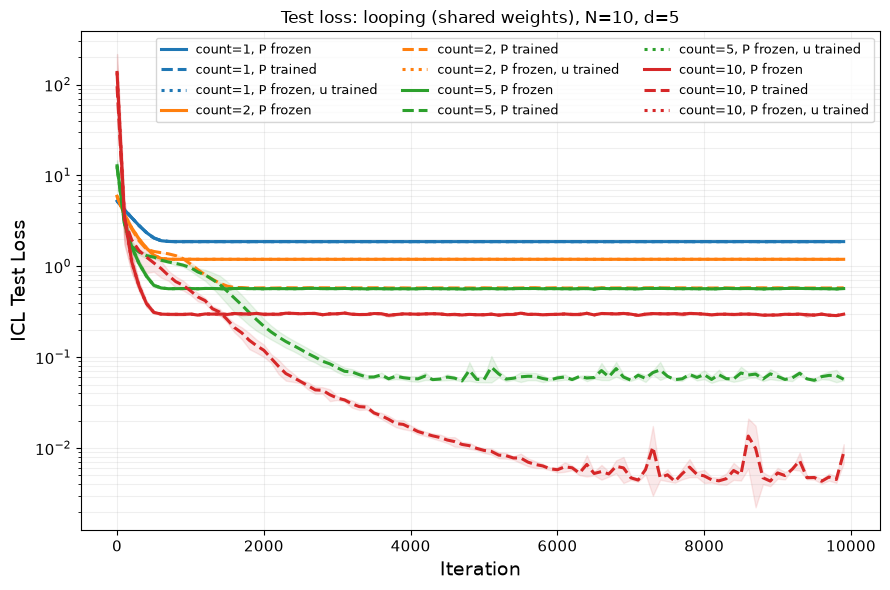

In [6]:
for model_type in model_types:
    overlay_plot(
        lambda setting, key: loss_dicts[setting][key].numpy(),
        iterations, model_type,
        ylabel='ICL Test Loss', title='Test loss',
        filename=f'test_loss_frozen_vs_trained_P_{model_type}_N{N}.pdf',
        log_scale=True,
    )

In [7]:
# Final test loss (mean ± std over seeds) for each configuration
print(f'{"model":<10}{"count":>6}' + ''.join(f'  {setting:>22}' for setting in P_SETTINGS))
for model_type in model_types:
    for count in n_layers_loops:
        row = f'{model_type:<10}{count:>6}'
        for setting in P_SETTINGS:
            keys = run_keys(loss_dicts[setting], count, model_type)
            finals = [loss_dicts[setting][key][-1].item() for key in keys]
            mean, std = seed_mean_std(np.array(finals)[:, None])
            row += f'  {mean[0]:>11.4g} ± {std[0]:<8.2g}'
        print(row)

model      count                P frozen               P trained     P frozen, u trained
looped         1        1.872 ± 0.0015          1.872 ± 0.0015          1.872 ± 0.0018  
looped         2        1.196 ± 0.00042        0.5806 ± 0.0018          1.196 ± 0.00056 
looped         5       0.5696 ± 0.0039        0.05724 ± 0.0015         0.5697 ± 0.004   
looped        10       0.2977 ± 0.0039       0.008926 ± 0.0021         0.2979 ± 0.004   


## Distance of A (= Q) to a scaled identity

With P frozen, the paper predicts A converges toward a multiple of the identity
(for isotropic covariates). This checks whether that still holds when P (or u) is free to move.

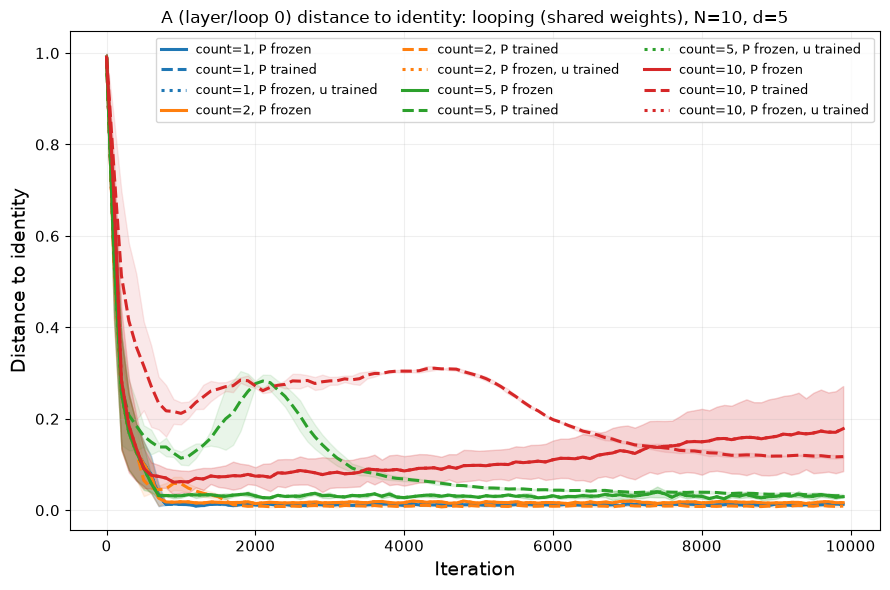

In [8]:
dist_dicts = {
    setting: compute_dist_dict(hist_dict, iterations, n_head, hist_stride=hist_stride)
    for setting, hist_dict in hist_dicts.items()
}

for model_type in model_types:
    overlay_plot(
        lambda setting, key: dist_dicts[setting][key][0, 1].numpy(),  # layer/loop 0, Q
        iterations, model_type,
        ylabel='Distance to identity', title='A (layer/loop 0) distance to identity',
        filename=f'dist_to_identity_A_frozen_vs_trained_P_{model_type}_N{N}.pdf',
    )

## How far does the trained P move from the frozen form?

Frobenius norm of P's learnable top-left $d \times d$ block, averaged over layers and heads.
For the runs with P frozen (including the u-trained runs) this is 0 throughout, so they serve as reference lines.

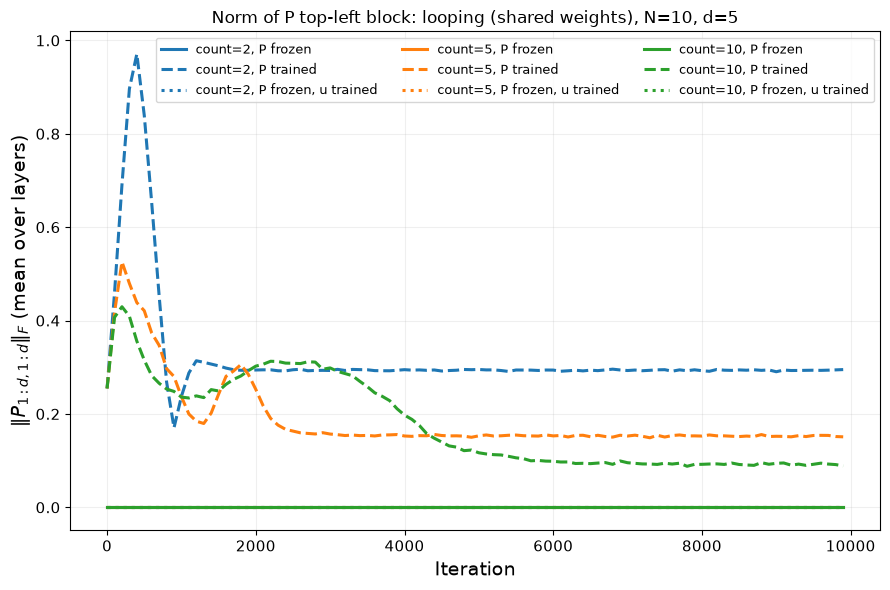

In [11]:
def p_block_norm_curve(hist_dict, key):
    history = hist_dict[key]
    curve = np.full(len(iterations), np.nan)
    for i, iteration in enumerate(iterations):
        if iteration % hist_stride != 0:
            continue
        index = iteration // hist_stride
        if index >= len(history):
            break
        snapshot = history[index]
        if not torch.isfinite(snapshot).all():
            continue
        # snapshot: (layers, heads, P/Q, d, d)
        curve[i] = torch.linalg.matrix_norm(snapshot[:, :, 0], ord='fro').mean().item()
    return curve


for model_type in model_types:
    overlay_plot(
        lambda setting, key: p_block_norm_curve(hist_dicts[setting], key),
        iterations, model_type,
        ylabel=r'$\|P_{1:d,1:d}\|_F$ (mean over layers)',
        title='Norm of P top-left block',
        filename=f'P_block_norm_frozen_vs_trained_P_{model_type}_N{N}.pdf',
    )

## Does training drive the bias u to 0?

Gatmiry et al. (2024, Theorem 4.1) show that the optimal bias is $u = 0$: any non-zero $u$ adds a
$w^*$-independent term to the prediction, which only increases the loss (Corollary A.4).
This plots $\|u\|_2$ (mean over heads) over training for the u-trained runs. It starts at
$\|u\| \approx \text{var}\cdot\sqrt{d}$ from the random initialization; with Adam it is expected to fall to
the optimizer's noise floor (roughly the learning rate) rather than exactly 0.

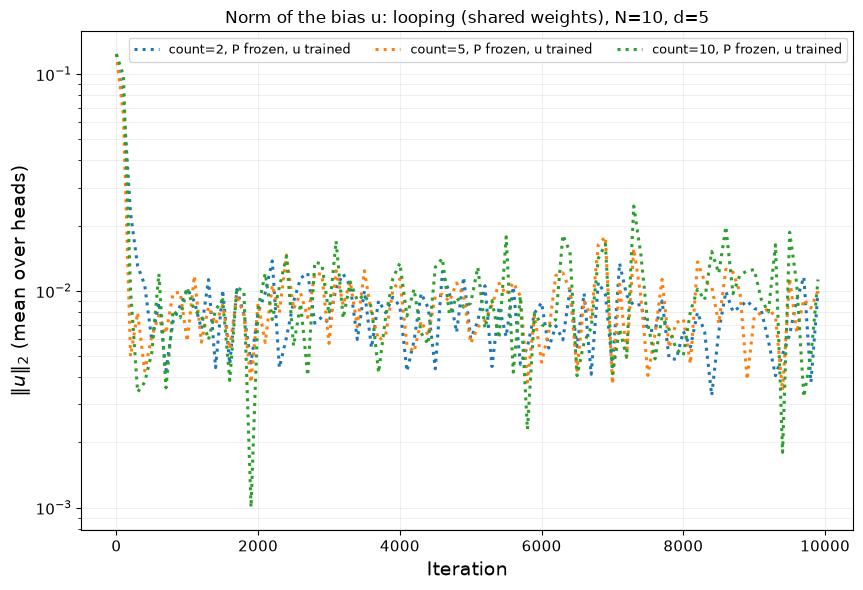

In [12]:
def u_norm_curve(u_history):
    curve = np.full(len(iterations), np.nan)
    for i, iteration in enumerate(iterations):
        if iteration % hist_stride != 0:
            continue
        index = iteration // hist_stride
        if index >= len(u_history):
            break
        snapshot = u_history[index]
        if not torch.isfinite(snapshot).all():
            continue
        # snapshot: (1, heads, d)
        curve[i] = torch.linalg.vector_norm(snapshot, dim=-1).mean().item()
    return curve


for model_type in model_types:
    overlay_plot(
        lambda setting, key: (u_norm_curve(u_hist_dicts[setting][key])
                              if setting in u_hist_dicts else None),
        iterations, model_type,
        ylabel=r'$\|u\|_2$ (mean over heads)',
        title='Norm of the bias u',
        filename=f'u_norm_{model_type}_N{N}.pdf',
        log_scale=True,
    )

In [13]:
# Initial and final ||u|| (mean ± std over seeds) for the u-trained runs
for setting, u_hist_dict in u_hist_dicts.items():
    print(setting)
    for count in n_layers_loops:
        keys = run_keys(u_hist_dict, count, 'looped')
        initial = np.array([torch.linalg.vector_norm(u_hist_dict[key][0], dim=-1).mean().item() for key in keys])
        final = np.array([torch.linalg.vector_norm(u_hist_dict[key][-1], dim=-1).mean().item() for key in keys])
        print(f'  count={count:>3}: initial {initial.mean():.3g}, final {final.mean():.3g} ± {final.std():.2g}')

P frozen, u trained
  count=  2: initial 0.124, final 0.00738 ± 0
  count=  5: initial 0.124, final 0.0102 ± 0
  count= 10: initial 0.124, final 0.00796 ± 0


## Learned matrices with P trained (seed 0)

Layer/loop-0 P and Q from the last checkpoint of the unconstrained runs.

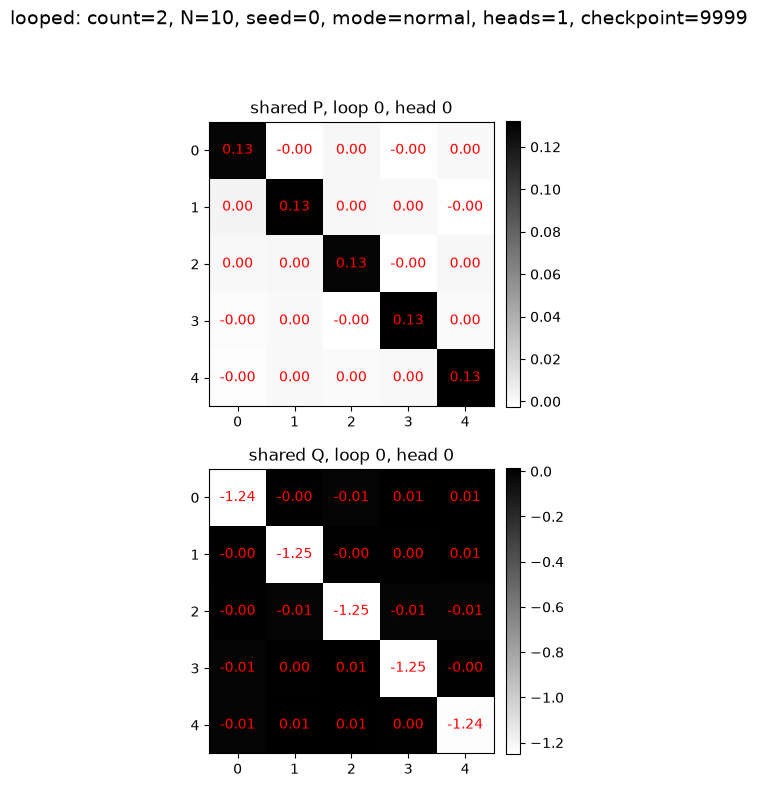

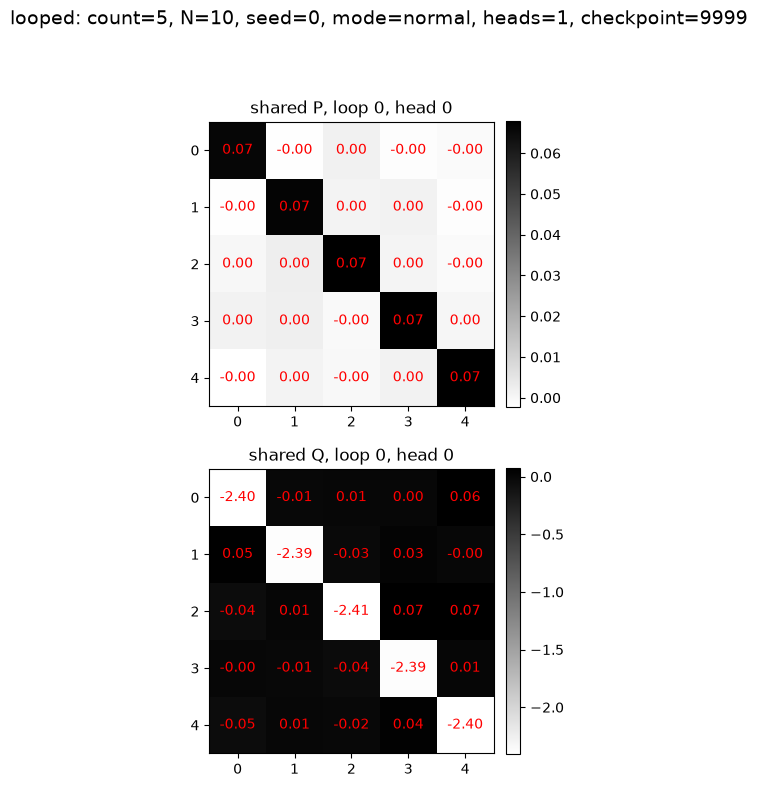

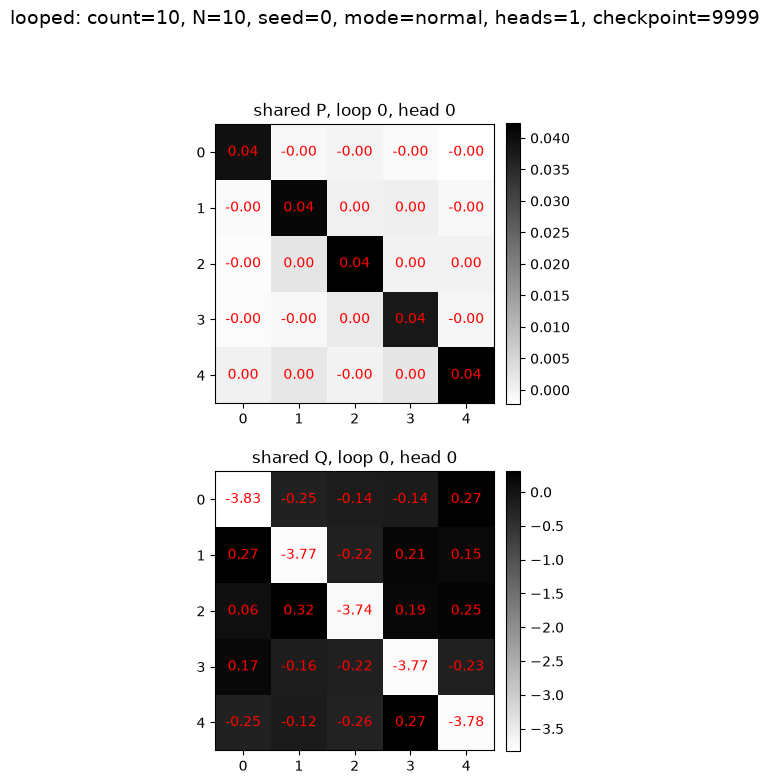

In [16]:
plot_parameter_matrices(hist_dicts['P trained'], seeds[0], n_layers_loops, model_types, n_head,
                        hist_stride=hist_stride, fig_dir=fig_dir)